In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
from pathlib import Path

data_folder = Path('/content/drive/MyDrive/DeepMinds')

X_train = pd.read_csv(data_folder / 'X_train.csv')
X_val   = pd.read_csv(data_folder / 'X_val.csv')
y_train = pd.read_csv(data_folder / 'y_train.csv')['label']
y_val   = pd.read_csv(data_folder / 'y_val.csv')['label']

print("Training:", X_train.shape, " Validation:", X_val.shape)
print("Phishing share (train):", round(y_train.mean() * 100, 2), "%")

Training: (165056, 50)  Validation: (35369, 50)
Phishing share (train): 42.81 %


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

def evaluate_model(name, split, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    results = {
        'Model': name, 'Split': split,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'False positives': int(fp),
        'False negatives': int(fn),
    }
    display(pd.DataFrame([results]).round(4))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing']
                           ).plot(cmap='Blues', values_format='d')
    plt.title(f'{name} — {split}'); plt.show()
    return results

Finished in 13 iterations


,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,Logistic Regression,Validation,0.9998,1.0,0.9995,0.9997,0,8


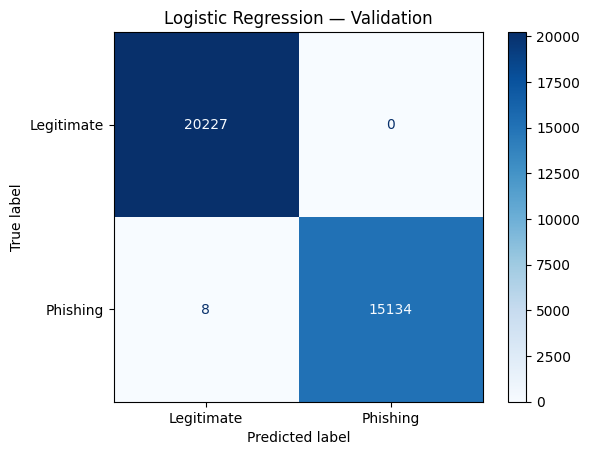

In [5]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
print("Finished in", lr.n_iter_[0], "iterations")

lr_results = evaluate_model('Logistic Regression', 'Validation', y_val, lr.predict(X_val))

,Weight
URLSimilarityIndex,-6.8788
IsHTTPS,-3.8337
SpacialCharRatioInURL,1.8447
LetterRatioInURL,1.7730
NoOfJS,-1.7447
HasSocialNet,-1.5048
NoOfSelfRef,-1.3611
NoOfImage,-1.2441
NoOfSubDomain,-1.2428
DegitRatioInURL,1.1973


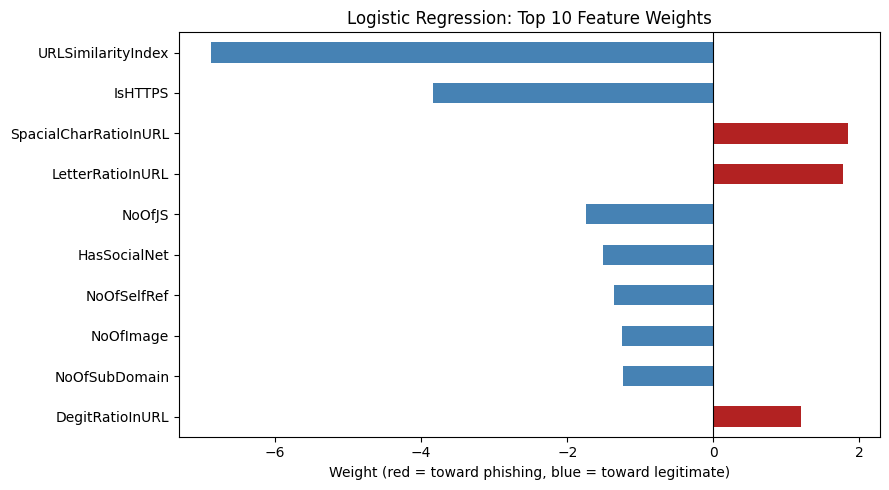

In [6]:
weights = pd.Series(lr.coef_[0], index=X_train.columns)
top_10 = weights.reindex(weights.abs().sort_values(ascending=False).index).head(10)
display(top_10.to_frame('Weight').round(4))

colors = ['firebrick' if w > 0 else 'steelblue' for w in top_10[::-1]]
top_10[::-1].plot.barh(color=colors, figsize=(9, 5))
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression: Top 10 Feature Weights')
plt.xlabel('Weight (red = toward phishing, blue = toward legitimate)')
plt.tight_layout()
plt.savefig(data_folder / 'lr_top_weights.png', dpi=200)
plt.show()

In [8]:
train_rows = set(pd.util.hash_pandas_object(X_train.round(6), index=False))
val_rows = pd.util.hash_pandas_object(X_val.round(6), index=False)
overlap = val_rows.isin(train_rows)
print(f"Validation rows identical to a training row: {overlap.sum():,} "
      f"of {len(X_val):,} ({overlap.mean()*100:.2f}%)")

Validation rows identical to a training row: 151 of 35,369 (0.43%)


,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,LR — URLSimilarityIndex only,Validation,0.9963,1.0,0.9913,0.9957,0,131


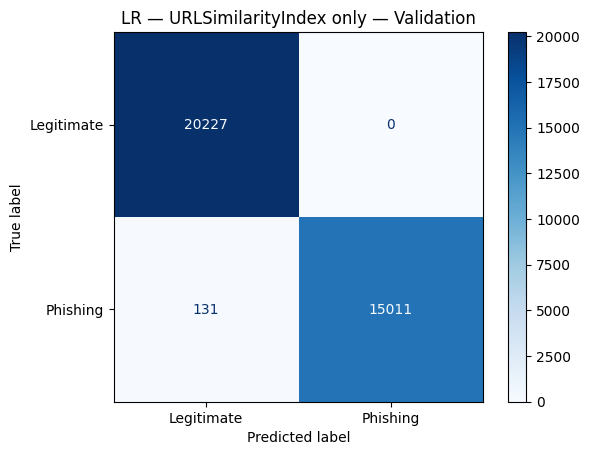

,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,LR — without URLSimilarityIndex,Validation,0.999,0.9993,0.9985,0.9989,11,23


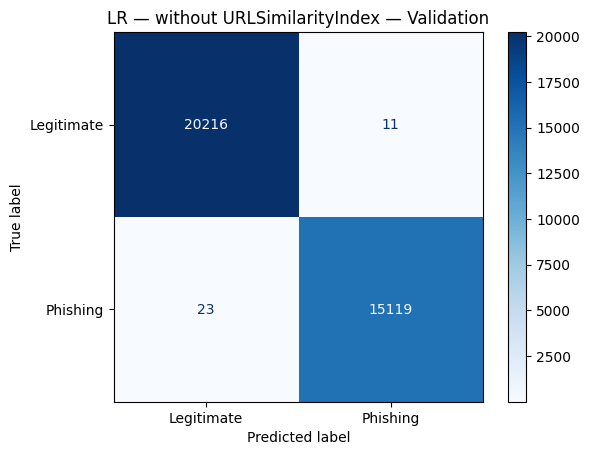

In [9]:
col = ['URLSimilarityIndex']

lr_only = LogisticRegression(max_iter=1000, random_state=42).fit(X_train[col], y_train)
only_results = evaluate_model('LR — URLSimilarityIndex only', 'Validation',
                              y_val, lr_only.predict(X_val[col]))

lr_without = LogisticRegression(max_iter=1000, random_state=42).fit(X_train.drop(columns=col), y_train)
without_results = evaluate_model('LR — without URLSimilarityIndex', 'Validation',
                                 y_val, lr_without.predict(X_val.drop(columns=col)))

In [10]:
lr_table = pd.DataFrame([lr_results, only_results, without_results])
display(lr_table.round(4))
lr_table.to_csv(data_folder / 'lr_results.csv', index=False)

,Model,Split,Accuracy,Precision,Recall,F1,False positives,False negatives
0,Logistic Regression,Validation,0.9998,1.0000,0.9995,0.9997,0,8
1,LR — URLSimilarityIndex only,Validation,0.9963,1.0000,0.9913,0.9957,0,131
2,LR — without URLSimilarityIndex,Validation,0.9990,0.9993,0.9985,0.9989,11,23
